# Exploration du dataset NF-UNSW-NB15-v3 (trafic réseau NetFlow)

**Source :** Luay, M. et al. (2025). *NF-UNSW-NB15-v3*. The University of Queensland. https://doi.org/10.48610/6e0eda1
(licence : usage non commercial, citation obligatoire)

Chaque ligne est un **flux réseau** (NetFlow v3, 53 features) étiqueté :
- `Label` : 0 = trafic normal (Benign), 1 = attaque
- `Attack` : la classe (Benign + 9 types d'attaques)

Plan :
1. Chargement & aperçu
2. Qualité des données (valeurs manquantes, doublons, colonnes constantes)
3. Variable cible : déséquilibre des classes
4. Dimension temporelle
5. Protocoles, ports et adresses IP
6. Distribution des features numériques (Benign vs Attaque)
7. Comparaison par type d'attaque
8. Corrélations
9. Importance des features (information mutuelle)
10. Projection 2D (PCA)
11. Synthèse

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Palette : couleurs catégorielles en ordre fixe (bleu, orange, aqua, jaune, magenta, vert, violet, rouge)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
C_BENIGN, C_ATTACK = PALETTE[0], PALETTE[1]
SEQ = "Blues"          # séquentiel : une seule teinte
DIV = "RdBu_r"         # divergent : deux teintes + milieu neutre

plt.rcParams.update({
    "figure.figsize": (11, 5), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 12,
})

DATA_DIR = Path("data")
CSV = DATA_DIR / "NF-UNSW-NB15-v3.csv"
FEATURES_DOC = DATA_DIR / "NetFlow_v3_Features.csv"

## 1. Chargement & aperçu

Le CSV fait ~580 Mo / 2,3 M lignes. On réduit les types numériques (`downcast`) pour diviser la mémoire.

In [2]:
%%time
df = pd.read_csv(CSV)
df.columns = df.columns.str.strip()

mem_before = df.memory_usage(deep=True).sum() / 1e6
for c in df.select_dtypes("integer").columns:
    df[c] = pd.to_numeric(df[c], downcast="integer") if df[c].min() < 0 else pd.to_numeric(df[c], downcast="unsigned")
for c in df.select_dtypes("float").columns:
    df[c] = pd.to_numeric(df[c], downcast="float")
for c in ["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "Attack"]:
    df[c] = df[c].astype("category")
mem_after = df.memory_usage(deep=True).sum() / 1e6
print(f"Forme : {df.shape}  |  mémoire {mem_before:,.0f} Mo -> {mem_after:,.0f} Mo")

Forme : (2365424, 55)  |  mémoire 1,401 Mo -> 324 Mo
CPU times: user 5.46 s, sys: 1.84 s, total: 7.3 s
Wall time: 7.88 s


In [3]:
df.head()

,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,FLOW_DURATION_MILLISECONDS,DURATION_IN,DURATION_OUT,MIN_TTL,MAX_TTL,LONGEST_FLOW_PKT,SHORTEST_FLOW_PKT,MIN_IP_PKT_LEN,MAX_IP_PKT_LEN,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_SECOND_BYTES,RETRANSMITTED_IN_BYTES,RETRANSMITTED_IN_PKTS,RETRANSMITTED_OUT_BYTES,RETRANSMITTED_OUT_PKTS,SRC_TO_DST_AVG_THROUGHPUT,DST_TO_SRC_AVG_THROUGHPUT,NUM_PKTS_UP_TO_128_BYTES,NUM_PKTS_128_TO_256_BYTES,NUM_PKTS_256_TO_512_BYTES,NUM_PKTS_512_TO_1024_BYTES,NUM_PKTS_1024_TO_1514_BYTES,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Label,Attack
0,1424242193040,1424242193043,59.166.0.2,4894,149.171.126.3,53,17,5.000,146,2,178,2,0,0,0,2,0,0,31,31,89,73,73,89,89.000,73.000,0,0,0,0,389333,474666,4,0,0,0,0,0,0,0,0,46779,1,60,0,0,0,0,0,0,0,0,0,0,Benign
1,1424242192744,1424242193079,59.166.0.4,52671,149.171.126.6,31992,6,11.000,4704,28,2976,28,27,27,27,335,334,334,31,32,984,52,52,984,8.884,14.042,1988,7,1068,6,112000,70857,34,18,2,2,0,14480,14480,50176,196,0,0,0,0,0,91,12,19,0,90,12,19,0,Benign
2,1424242190649,1424242193109,59.166.0.0,47290,149.171.126.9,6881,6,37.000,13662,238,548216,438,27,27,27,2460,2459,2459,31,32,1500,52,52,1500,222.852,5.554,1735,21,272908,196,44411,1782091,288,0,4,32,352,65160,34752,50944,199,0,0,0,0,0,1843,10,119,0,1843,5,88,0,Benign
3,1424242193145,1424242193146,59.166.0.8,43310,149.171.126.7,53,17,5.000,146,2,178,2,0,0,0,1,0,0,31,31,89,73,73,89,178.000,146.000,0,0,0,0,584000,712000,4,0,0,0,0,0,0,0,0,3211,1,60,0,0,0,0,0,0,0,0,0,0,Benign
4,1424242193239,1424242193241,59.166.0.1,45870,149.171.126.1,53,17,5.000,130,2,162,2,0,0,0,1,0,0,31,31,81,65,65,81,162.000,130.000,0,0,0,0,520000,648000,4,0,0,0,0,0,0,0,0,5771,1,60,0,0,0,0,0,0,0,0,0,0,Benign


In [4]:
# Description officielle des features
doc = pd.read_csv(FEATURES_DOC, encoding="utf-8-sig")
doc["Feature"] = doc["Feature"].str.strip()
doc = doc.set_index("Feature")["Description"]
info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "description": doc.reindex(df.columns).fillna(""),
})
info

,dtype,n_unique,description
FLOW_START_MILLISECONDS,uint64,1893404,Flow start timestamp in milliseconds
FLOW_END_MILLISECONDS,uint64,2299732,Flow end timestamp in milliseconds
IPV4_SRC_ADDR,category,40,IPv4 source address
L4_SRC_PORT,uint16,64597,IPv4 source port number
IPV4_DST_ADDR,category,40,IPv4 destination address
L4_DST_PORT,uint16,64617,IPv4 destination port number
PROTOCOL,uint8,255,IP protocol identifier byte
L7_PROTO,float32,141,Layer 7 protocol (numeric)
IN_BYTES,uint32,13658,Incoming number of bytes
IN_PKTS,uint16,892,Incoming number of packets


Les features se regroupent en familles :

| Famille | Colonnes |
|---|---|
| Identifiants | `IPV4_SRC_ADDR`, `IPV4_DST_ADDR`, `L4_SRC_PORT`, `L4_DST_PORT` |
| Protocole | `PROTOCOL`, `L7_PROTO`, `ICMP_*`, `DNS_*`, `FTP_COMMAND_RET_CODE` |
| Volume | `IN/OUT_BYTES`, `IN/OUT_PKTS`, `NUM_PKTS_*`, `RETRANSMITTED_*` |
| Temps | `FLOW_START/END_MILLISECONDS`, `FLOW_DURATION_MILLISECONDS`, `DURATION_IN/OUT`, `*_IAT_*` |
| TCP | `TCP_FLAGS`, `CLIENT/SERVER_TCP_FLAGS`, `TCP_WIN_MAX_*` |
| Paquets | `MIN/MAX_TTL`, `LONGEST/SHORTEST_FLOW_PKT`, `MIN/MAX_IP_PKT_LEN` |
| Débit | `*_SECOND_BYTES`, `*_AVG_THROUGHPUT` |
| Cible | `Label`, `Attack` |

## 2. Qualité des données

In [5]:
missing = df.isna().sum()
print("Valeurs manquantes :", int(missing.sum()))
display(missing[missing > 0])

num = df.select_dtypes("number")
inf = np.isinf(num.select_dtypes("float")).sum()
print("Valeurs infinies :", int(inf.sum()))
display(inf[inf > 0])

neg = (num < 0).sum()
print("Colonnes avec valeurs négatives :")
display(neg[neg > 0])

Valeurs manquantes : 63425


SRC_TO_DST_SECOND_BYTES    63425
dtype: int64

Valeurs infinies : 181561


SRC_TO_DST_SECOND_BYTES     59068
DST_TO_SRC_SECOND_BYTES    122493
dtype: int64

Colonnes avec valeurs négatives :


Series([], dtype: int64)

Les colonnes `SRC_TO_DST_SECOND_BYTES` / `DST_TO_SRC_SECOND_BYTES` (octets/seconde) contiennent des **NaN et des infinis** :
vérifions s'ils viennent de flux de durée nulle (division par 0).

In [6]:
rate_cols = ["SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"]
for c in rate_cols:
    bad = ~np.isfinite(df[c])
    print(f"{c}: {bad.sum():,} valeurs non finies "
          f"(dont NaN {df[c].isna().sum():,}) | durée du flux = 0 pour {(df.loc[bad, 'FLOW_DURATION_MILLISECONDS'] == 0).mean():.1%} d'entre elles")
    display(df.loc[bad, "Attack"].value_counts().head(5).to_frame(f"{c} non fini"))

# Nettoyage : débit indéfini (durée nulle) -> 0, et on garde un indicateur
df["RATE_UNDEFINED"] = (~np.isfinite(df[rate_cols])).any(axis=1).astype("uint8")
df[rate_cols] = df[rate_cols].replace([np.inf, -np.inf], np.nan).fillna(0)
print("Non finis restants :", int((~np.isfinite(df.select_dtypes('float'))).sum().sum()))

SRC_TO_DST_SECOND_BYTES: 122,493 valeurs non finies (dont NaN 63,425) | durée du flux = 0 pour 100.0% d'entre elles


,SRC_TO_DST_SECOND_BYTES non fini
Attack,
Benign,86704
Generic,14891
Fuzzers,8228
Reconnaissance,5783
Exploits,3932


DST_TO_SRC_SECOND_BYTES: 122,493 valeurs non finies (dont NaN 0) | durée du flux = 0 pour 100.0% d'entre elles


,DST_TO_SRC_SECOND_BYTES non fini
Attack,
Benign,86704
Generic,14891
Fuzzers,8228
Reconnaissance,5783
Exploits,3932


Non finis restants : 0


In [7]:
%%time
dup_all = df.duplicated().sum()
# Doublons en ignorant les identifiants/temps : même "forme" de flux
id_cols = ["FLOW_START_MILLISECONDS", "FLOW_END_MILLISECONDS", "IPV4_SRC_ADDR", "IPV4_DST_ADDR",
           "L4_SRC_PORT", "L4_DST_PORT", "DNS_QUERY_ID"]
feat_cols = [c for c in df.columns if c not in id_cols + ["Label", "Attack", "RATE_UNDEFINED"]]
dup_feat = df.duplicated(subset=feat_cols).sum()
# Même vecteur de features mais labels différents -> bruit irréductible pour un classifieur
conflict = (df.groupby(feat_cols, observed=True)["Label"].nunique() > 1).sum()
print(f"Lignes strictement dupliquées           : {dup_all:,} ({dup_all/len(df):.2%})")
print(f"Doublons sur les features (hors id/temps): {dup_feat:,} ({dup_feat/len(df):.2%})")
print(f"Vecteurs de features avec labels en conflit : {conflict:,}")

Lignes strictement dupliquées           : 14,815 (0.63%)
Doublons sur les features (hors id/temps): 1,303,827 (55.12%)
Vecteurs de features avec labels en conflit : 0
CPU times: user 4.62 s, sys: 1.39 s, total: 6 s
Wall time: 6.36 s


In [8]:
nun = df.nunique()
const = nun[nun <= 1]
print("Colonnes constantes :", list(const.index))
low = nun[(nun > 1) & (nun <= 10)].sort_values()
print("Colonnes à très faible cardinalité (<=10) :")
low

Colonnes constantes : []
Colonnes à très faible cardinalité (<=10) :


Label              2
RATE_UNDEFINED     2
Attack            10
dtype: int64

## 3. Variable cible : déséquilibre des classes

In [9]:
counts = df["Attack"].value_counts()
target = pd.DataFrame({"n_flux": counts, "pct": counts / len(df) * 100})
print(df["Label"].value_counts(normalize=True).rename({0: "Benign", 1: "Attack"}).map("{:.2%}".format))
target

Label
Benign    94.60%
Attack     5.40%
Name: proportion, dtype: object


,n_flux,pct
Attack,,
Benign,2237731,94.602
Exploits,42748,1.807
Fuzzers,33816,1.430
Generic,19651,0.831
Reconnaissance,17074,0.722
DoS,5980,0.253
Backdoor,4659,0.197
Shellcode,2381,0.101
Analysis,1226,0.052


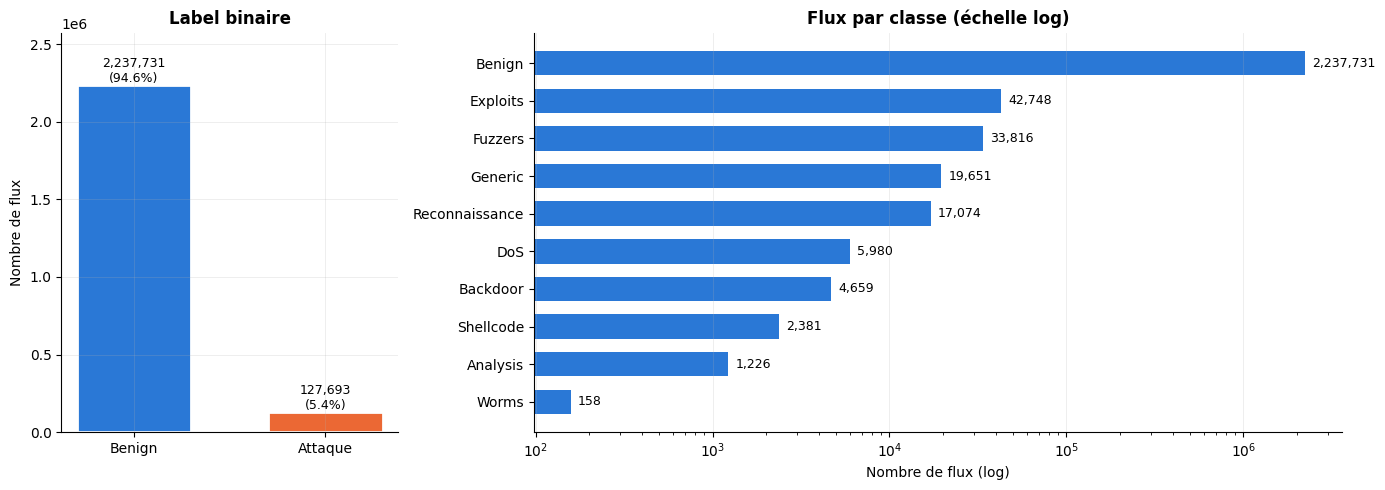

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 2.4]})

lab = df["Label"].value_counts().sort_index()
axes[0].bar(["Benign", "Attaque"], lab.values, color=[C_BENIGN, C_ATTACK], width=0.6, edgecolor="white", linewidth=2)
for i, v in enumerate(lab.values):
    axes[0].text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom", fontsize=9)
axes[0].set_title("Label binaire")
axes[0].set_ylabel("Nombre de flux")
axes[0].margins(y=0.15)

c = counts.sort_values()
axes[1].barh(c.index.astype(str), c.values, color=C_BENIGN, height=0.65)
axes[1].set_xscale("log")
for y, v in enumerate(c.values):
    axes[1].text(v * 1.1, y, f"{v:,}", va="center", fontsize=9)
axes[1].set_title("Flux par classe (échelle log)")
axes[1].set_xlabel("Nombre de flux (log)")
axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

> **À retenir :** le dataset est très déséquilibré. Pour la modélisation il faudra une métrique adaptée
> (F1 macro, rappel par classe, PR-AUC) plutôt que l'accuracy, un split **stratifié**, et éventuellement
> du re-échantillonnage / des poids de classes.

## 4. Dimension temporelle

Les timestamps sont en millisecondes Unix. On regarde quand le trafic (et les attaques) se produisent.

In [11]:
df["start"] = pd.to_datetime(df["FLOW_START_MILLISECONDS"], unit="ms")
df["end"] = pd.to_datetime(df["FLOW_END_MILLISECONDS"], unit="ms")
print("Période couverte :", df["start"].min(), "->", df["end"].max())
print("Durée totale     :", df["end"].max() - df["start"].min())
print("Flux avec fin < début :", int((df["end"] < df["start"]).sum()))
print("Écart FLOW_DURATION vs (fin - début), médiane absolue (ms) :",
      (df["FLOW_DURATION_MILLISECONDS"].astype("int64") - (df["FLOW_END_MILLISECONDS"] - df["FLOW_START_MILLISECONDS"])).abs().median())

Période couverte : 2015-01-22 11:49:36.907000 -> 2015-02-18 12:29:25.011000
Durée totale     : 27 days 00:39:48.104000
Flux avec fin < début : 0
Écart FLOW_DURATION vs (fin - début), médiane absolue (ms) : 0.0


In [12]:
# Les données proviennent de plusieurs sessions de capture : on les sépare (trou > 1 h)
starts = df["start"].sort_values()
gaps = starts.diff() > pd.Timedelta("1h")
session_bounds = starts[gaps | (starts.index == starts.index[0])].tolist()
df["session"] = np.searchsorted(np.array(session_bounds, dtype="datetime64[ns]"), df["start"].values, side="right")
sess = df.groupby("session").agg(debut=("start", "min"), fin=("end", "max"), n_flux=("Label", "size"),
                                 pct_attaque=("Label", "mean"))
sess["duree"] = sess["fin"] - sess["debut"]
sess["pct_attaque"] *= 100
sess

,debut,fin,n_flux,pct_attaque,duree
session,,,,,
1,2015-01-22 11:49:36.907,2015-01-23 00:25:23.813,1135352,1.538,0 days 12:35:46.906000
2,2015-02-18 00:23:27.658,2015-02-18 12:29:25.011,1230072,8.961,0 days 12:05:57.353000


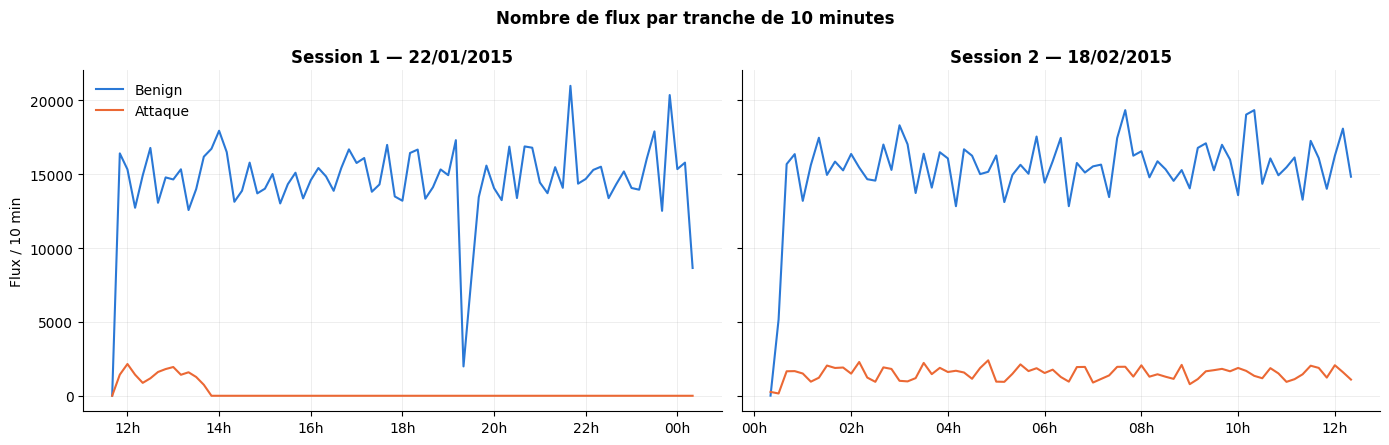

In [13]:
fig, axes = plt.subplots(1, len(sess), figsize=(14, 4.5), sharey=True, squeeze=False)
for ax, (sid, g) in zip(axes[0], df.groupby("session")):
    ts = (g.set_index("start").groupby([pd.Grouper(freq="10min"), "Label"]).size()
            .unstack(fill_value=0).reindex(columns=[0, 1], fill_value=0))
    ax.plot(ts.index, ts[0], color=C_BENIGN, lw=1.5, label="Benign")
    ax.plot(ts.index, ts[1], color=C_ATTACK, lw=1.5, label="Attaque")
    ax.set_title(f"Session {sid} — {g['start'].min():%d/%m/%Y}")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Hh"))
axes[0, 0].set_ylabel("Flux / 10 min")
axes[0, 0].legend(frameon=False)
fig.suptitle("Nombre de flux par tranche de 10 minutes", fontweight="bold")
plt.tight_layout(); plt.show()

Vue par type d'attaque (seules les tranches de 30 min contenant du trafic sont affichées) :

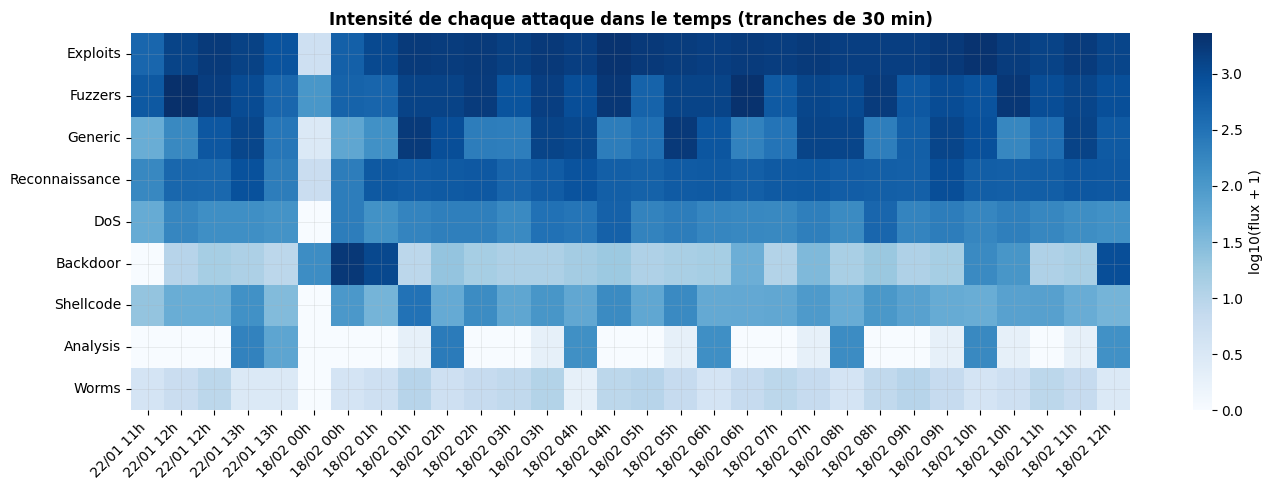

In [14]:
attacks = [a for a in counts.index if a != "Benign"]
ts_att = (df[df["Label"] == 1].set_index("start")
            .groupby([pd.Grouper(freq="30min"), "Attack"], observed=True)
            .size().unstack(fill_value=0))
ts_att = ts_att[ts_att.sum(axis=1) > 0]

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(np.log10(ts_att[attacks].T + 1), cmap=SEQ, ax=ax,
            cbar_kws={"label": "log10(flux + 1)"})
step = max(1, len(ts_att) // 20)
ax.set_xticks(np.arange(0, len(ts_att), step) + 0.5)
ax.set_xticklabels(ts_att.index[::step].strftime("%d/%m %Hh"), rotation=45, ha="right")
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title("Intensité de chaque attaque dans le temps (tranches de 30 min)")
plt.tight_layout(); plt.show()

> **À retenir :** deux sessions de capture (22/01/2015 et 18/02/2015, ~12 h chacune, comme dans l'UNSW-NB15 d'origine).
> Session 1 : attaques seulement pendant les ~2 premières heures (1,5 % des flux). Session 2 : attaques continues pendant 12 h (9 % des flux).
> Les deux sessions n'ont donc pas la même distribution, ce qui fait d'un train/test par session un bon test de généralisation.
> Attention toutefois : si on fait un split aléatoire, des flux quasi identiques et contemporains se retrouvent
> en train et en test → score optimiste. Un **split temporel** est un bon test de robustesse.

## 5. Protocoles, ports et adresses IP

proto_name
TCP            1805270
UDP             556557
Autre (89)        1407
ICMP               401
Autre (132)         73
Autre (2)           33
Autre (47)          14
Autre (103)         14
Autre (53)          13
Autre (55)          13
Name: count, dtype: int64


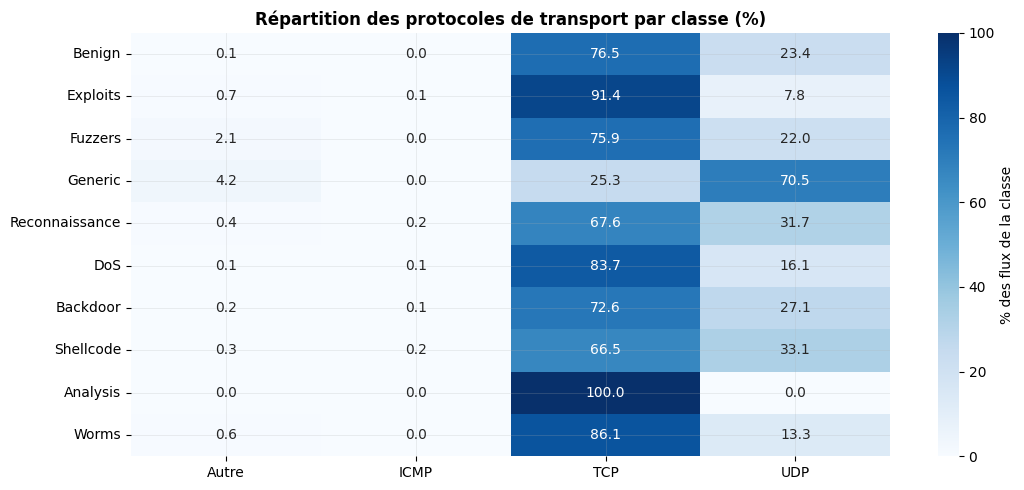

In [15]:
proto_names = {6: "TCP", 17: "UDP", 1: "ICMP"}
df["proto_name"] = df["PROTOCOL"].map(proto_names).fillna("Autre (" + df["PROTOCOL"].astype(str) + ")")
top_protos = df["proto_name"].value_counts()
print(top_protos.head(10))

ct = pd.crosstab(df["Attack"], df["proto_name"].where(df["proto_name"].isin(["TCP", "UDP", "ICMP"]), "Autre"),
                 normalize="index") * 100
ct = ct.loc[counts.index]
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(ct, annot=True, fmt=".1f", cmap=SEQ, ax=ax, cbar_kws={"label": "% des flux de la classe"})
ax.set_title("Répartition des protocoles de transport par classe (%)")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

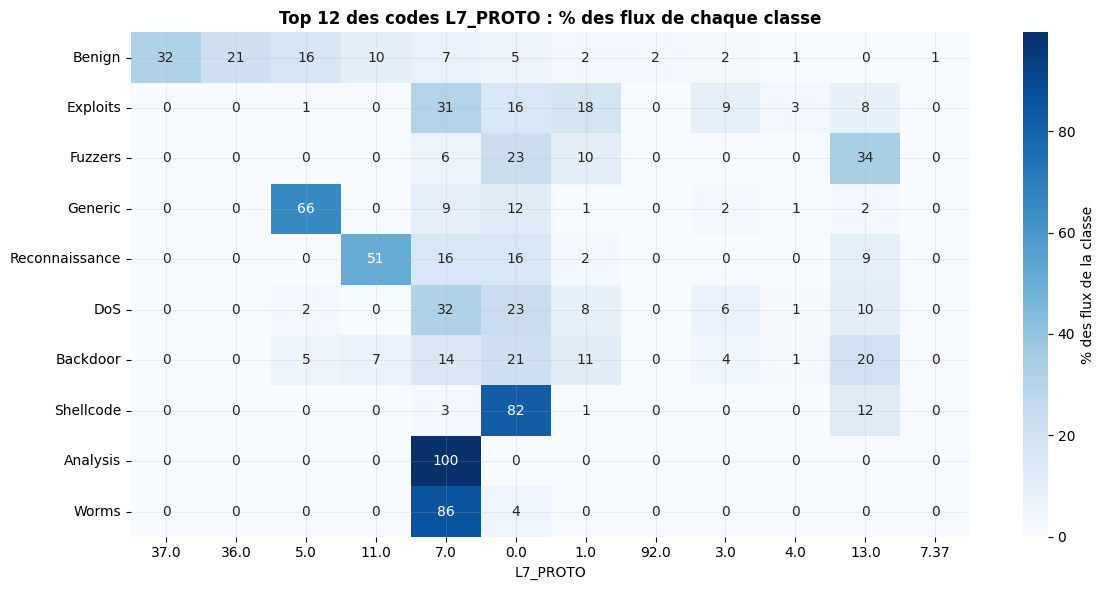

In [16]:
# L7_PROTO : protocole applicatif détecté par nDPI (code numérique)
l7 = pd.crosstab(df["L7_PROTO"], df["Attack"])
top_l7 = l7.sum(axis=1).nlargest(12).index
l7_pct = (l7.loc[top_l7] / l7.sum()) * 100
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(l7_pct[counts.index].T, annot=True, fmt=".0f", cmap=SEQ, ax=ax, cbar_kws={"label": "% des flux de la classe"})
ax.set_title("Top 12 des codes L7_PROTO : % des flux de chaque classe")
ax.set_xlabel("L7_PROTO"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

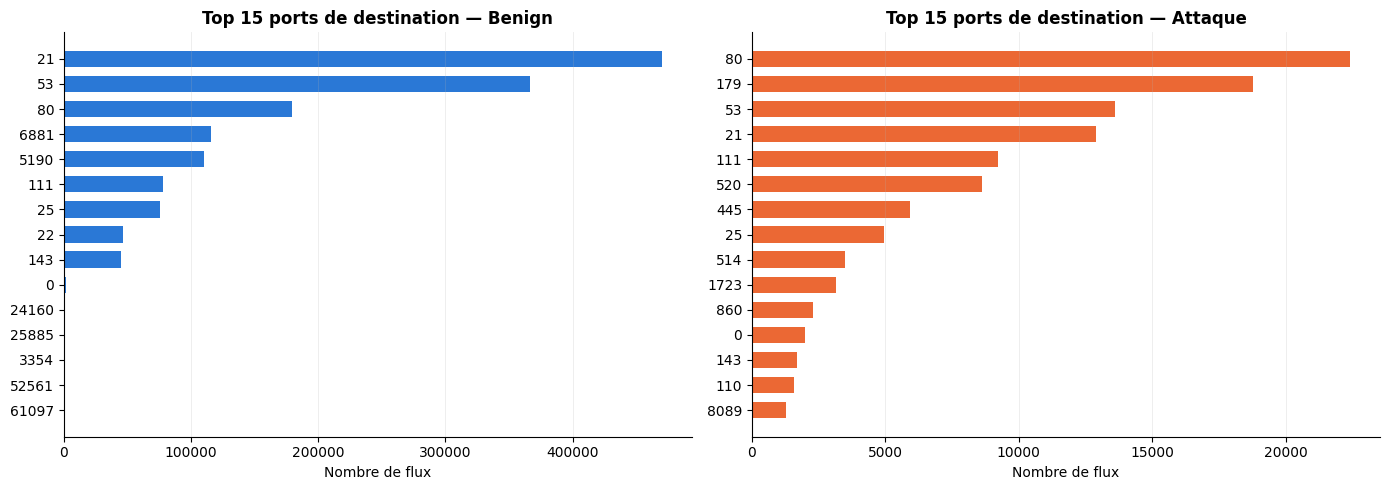

Ports destination distincts par classe :


Attack
Benign            64516
Exploits           2472
Shellcode          1449
Reconnaissance      707
Generic             686
DoS                 363
Fuzzers             325
Backdoor            282
Worms                11
Analysis              2
Name: L4_DST_PORT, dtype: int64

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, lbl, color, name in [(axes[0], 0, C_BENIGN, "Benign"), (axes[1], 1, C_ATTACK, "Attaque")]:
    p = df.loc[df["Label"] == lbl, "L4_DST_PORT"].value_counts().head(15).sort_values()
    ax.barh(p.index.astype(str), p.values, color=color, height=0.65)
    ax.set_title(f"Top 15 ports de destination — {name}")
    ax.set_xlabel("Nombre de flux")
    ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

print("Ports destination distincts par classe :")
df.groupby("Attack", observed=True)["L4_DST_PORT"].nunique().sort_values(ascending=False)

In [18]:
# Adresses IP : UNSW-NB15 utilise des sous-réseaux bien identifiés (59.166.0.x, 149.171.126.x, 175.45.176.x ...)
def subnet(s):
    return s.astype(str).str.rsplit(".", n=1).str[0] + ".0/24"

df["src_subnet"] = subnet(df["IPV4_SRC_ADDR"])
df["dst_subnet"] = subnet(df["IPV4_DST_ADDR"])

src_ct = pd.crosstab(df["src_subnet"], df["Label"]).rename(columns={0: "Benign", 1: "Attaque"})
src_ct["% attaque"] = src_ct["Attaque"] / src_ct.sum(axis=1) * 100
print("Sous-réseaux source les plus actifs :")
display(src_ct.sort_values("Benign", ascending=False).head(10))

print("Nombre d'IP source distinctes :", df["IPV4_SRC_ADDR"].nunique(),
      "| IP destination :", df["IPV4_DST_ADDR"].nunique())

Sous-réseaux source les plus actifs :


Label,Benign,Attaque,% attaque
src_subnet,,,
59.166.0.0/24,2205164,0,0.000
149.171.126.0/24,30696,0,0.000
10.40.85.0/24,1144,0,0.000
10.40.182.0/24,700,0,0.000
192.168.241.0/24,26,0,0.000
127.0.0.0/24,1,0,0.000
175.45.176.0/24,0,127693,100.000


Nombre d'IP source distinctes : 40 | IP destination : 40


In [19]:
src_by_label = df.groupby("IPV4_SRC_ADDR", observed=True)["Label"].agg(["count", "mean"])
src_by_label = src_by_label[src_by_label["count"] > 0]
print("IP sources 100 % attaque :", int((src_by_label["mean"] == 1).sum()))
print("IP sources 100 % benign  :", int((src_by_label["mean"] == 0).sum()))
print("IP sources mixtes        :", int(((src_by_label["mean"] > 0) & (src_by_label["mean"] < 1)).sum()))
src_by_label.sort_values("count", ascending=False).head(15)

IP sources 100 % attaque : 4
IP sources 100 % benign  : 36
IP sources mixtes        : 0


,count,mean
IPV4_SRC_ADDR,,
59.166.0.2,225316,0.000
59.166.0.4,224942,0.000
59.166.0.1,224766,0.000
59.166.0.0,224274,0.000
59.166.0.3,223608,0.000
59.166.0.5,222835,0.000
59.166.0.9,215681,0.000
59.166.0.8,215238,0.000
59.166.0.7,214339,0.000


> **⚠️ Fuite d'information :** dans UNSW-NB15, les attaquants proviennent de sous-réseaux spécifiques.
> Un modèle qui reçoit les IP (ou les ports sources/timestamps) peut apprendre « qui » attaque plutôt que « comment »
> et ne généralisera pas à un autre réseau. On exclut généralement `IPV4_SRC_ADDR`, `IPV4_DST_ADDR`,
> `L4_SRC_PORT`, `FLOW_START/END_MILLISECONDS` des features d'entraînement.

## 6. Distribution des features numériques (Benign vs Attaque)

In [20]:
drop_for_model = ["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "L4_SRC_PORT", "FLOW_START_MILLISECONDS",
                  "FLOW_END_MILLISECONDS", "Label", "Attack", "start", "end",
                  "proto_name", "src_subnet", "dst_subnet"]
num_cols = [c for c in df.select_dtypes("number").columns if c not in drop_for_model]
print(len(num_cols), "features numériques candidates")
df[num_cols].describe(percentiles=[.25, .5, .75, .99]).T

50 features numériques candidates


,count,mean,std,min,25%,50%,75%,99%,max
L4_DST_PORT,"2,365,424.000","11,148.406","18,394.243",0.000,25.000,80.000,"14,629.250","63,622.000","65,535.000"
PROTOCOL,"2,365,424.000",8.731,6.385,0.000,6.000,6.000,6.000,17.000,255.000
L7_PROTO,"2,365,424.000",23.532,21.323,0.000,5.000,36.000,37.000,92.000,421.000
IN_BYTES,"2,365,424.000","4,413.591","67,699.448",1.000,481.000,"1,580.000","3,048.000","37,462.000","27,020,934.000"
IN_PKTS,"2,365,424.000",35.282,78.393,1.000,4.000,16.000,44.000,356.000,"20,166.000"
OUT_BYTES,"2,365,424.000","34,320.028","155,073.241",0.000,312.000,"2,456.000","14,370.000","1,087,890.000","14,656,752.000"
OUT_PKTS,"2,365,424.000",44.711,116.344,0.000,4.000,18.000,42.000,746.000,"11,024.000"
TCP_FLAGS,"2,365,424.000",19.765,11.158,0.000,19.000,27.000,27.000,27.000,31.000
CLIENT_TCP_FLAGS,"2,365,424.000",19.486,11.073,0.000,19.000,25.000,27.000,27.000,31.000
SERVER_TCP_FLAGS,"2,365,424.000",19.362,11.110,0.000,16.000,27.000,27.000,27.000,31.000


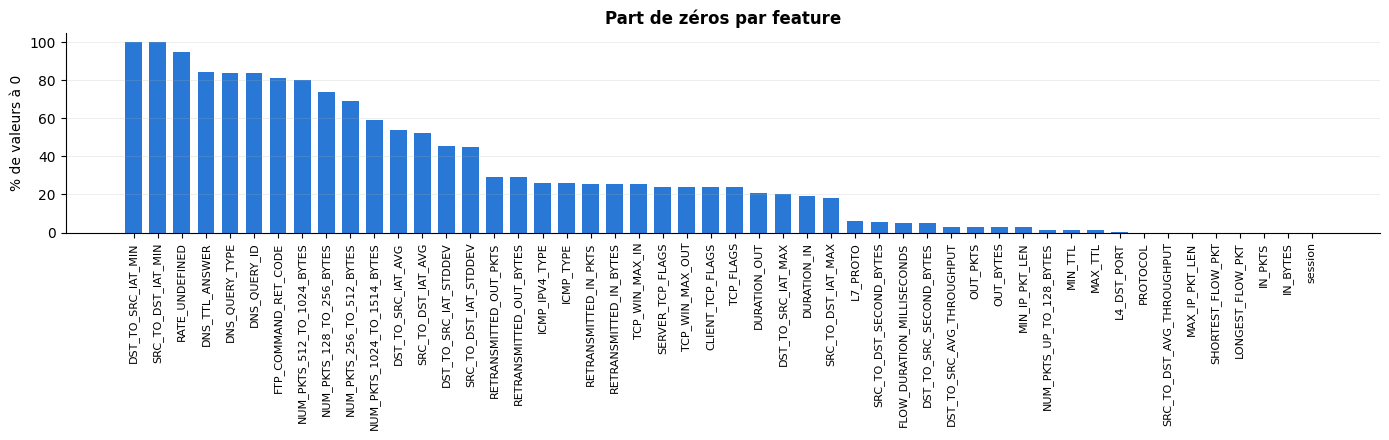

In [21]:
# Proportion de zéros : beaucoup de features sont très creuses
zeros = (df[num_cols] == 0).mean().sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.bar(zeros.index, zeros.values, color=C_BENIGN, width=0.7)
ax.set_ylabel("% de valeurs à 0")
ax.set_title("Part de zéros par feature")
ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

In [22]:
# Échantillon stratifié pour les graphiques (plus rapide, lisible)
SAMPLE_PER_CLASS = 20_000
shuffled = df.sample(frac=1, random_state=42)
sample = shuffled.groupby("Attack", observed=True).head(SAMPLE_PER_CLASS)
print(sample["Attack"].value_counts())

Attack
Benign            20000
Exploits          20000
Fuzzers           20000
Generic           19651
Reconnaissance    17074
DoS                5980
Backdoor           4659
Shellcode          2381
Analysis           1226
Worms               158
Name: count, dtype: int64


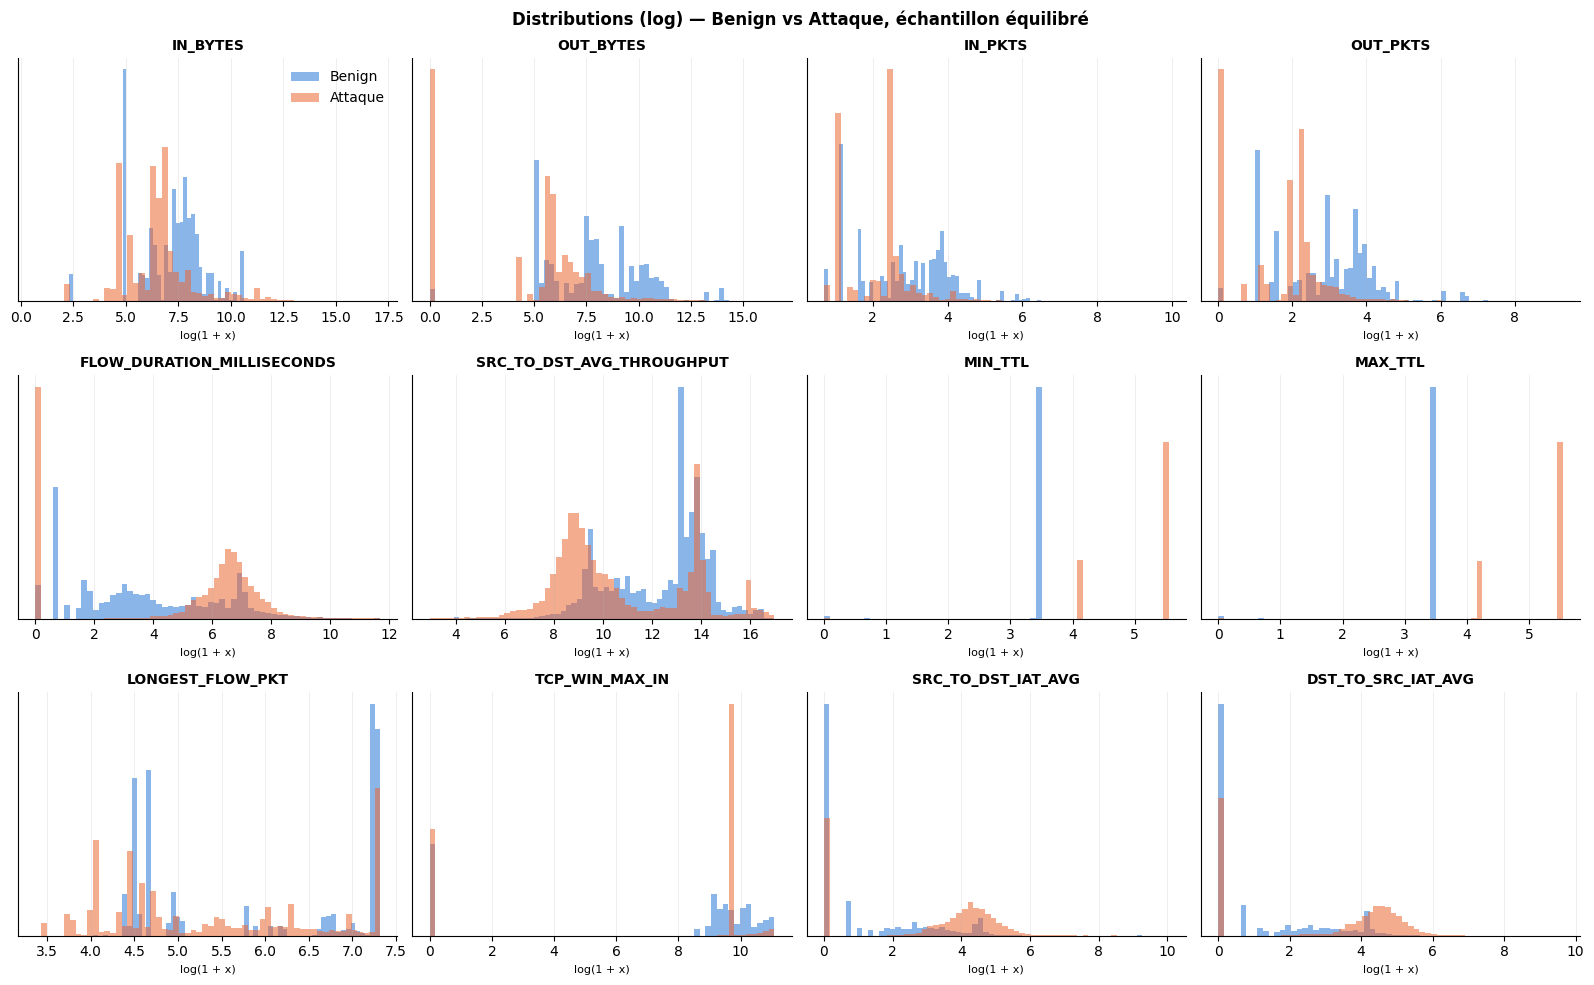

In [23]:
key_feats = ["IN_BYTES", "OUT_BYTES", "IN_PKTS", "OUT_PKTS", "FLOW_DURATION_MILLISECONDS",
             "SRC_TO_DST_AVG_THROUGHPUT", "MIN_TTL", "MAX_TTL", "LONGEST_FLOW_PKT",
             "TCP_WIN_MAX_IN", "SRC_TO_DST_IAT_AVG", "DST_TO_SRC_IAT_AVG"]

# Échantillon équilibré binaire pour comparer les distributions
bin_sample = shuffled.groupby("Label").head(50_000)

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, key_feats):
    for lbl, color, name in [(0, C_BENIGN, "Benign"), (1, C_ATTACK, "Attaque")]:
        v = np.log1p(bin_sample.loc[bin_sample["Label"] == lbl, col].astype(float))
        ax.hist(v, bins=60, color=color, alpha=0.55, density=True, label=name)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("log(1 + x)", fontsize=8)
    ax.set_yticks([])
axes.flat[0].legend(frameon=False)
fig.suptitle("Distributions (log) — Benign vs Attaque, échantillon équilibré", fontweight="bold")
plt.tight_layout(); plt.show()

## 7. Comparaison par type d'attaque

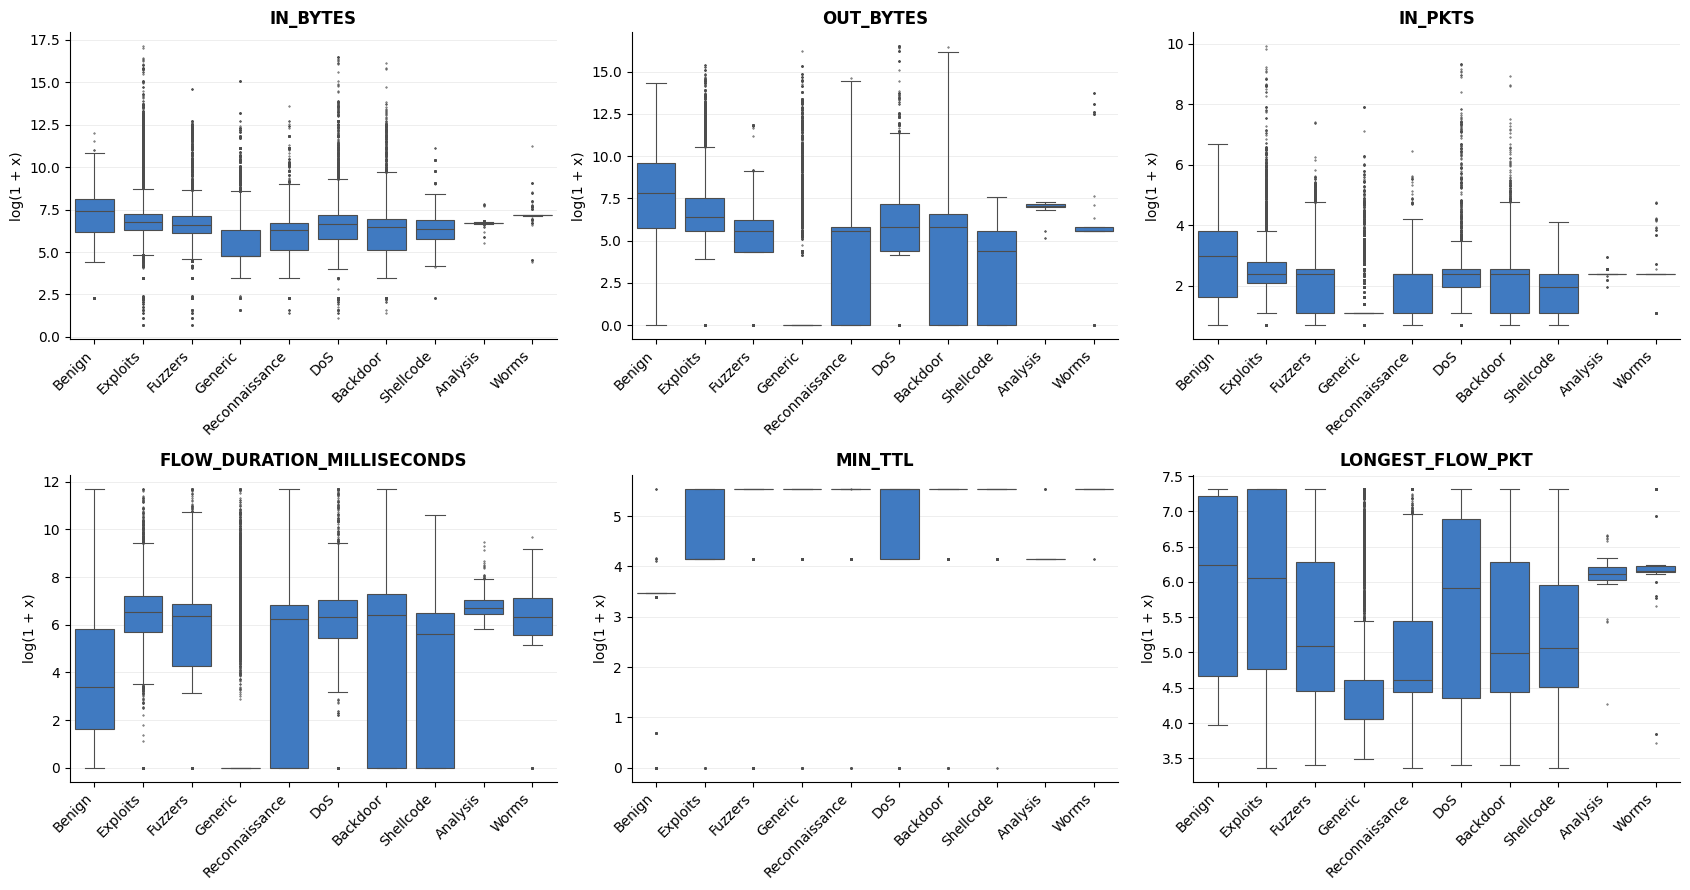

In [24]:
order = counts.index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col in zip(axes.flat, ["IN_BYTES", "OUT_BYTES", "IN_PKTS", "FLOW_DURATION_MILLISECONDS", "MIN_TTL", "LONGEST_FLOW_PKT"]):
    sns.boxplot(data=sample, x="Attack", y=np.log1p(sample[col].astype(float)), order=order,
                color=C_BENIGN, fliersize=0.5, linewidth=0.8, ax=ax)
    ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("log(1 + x)")
    ax.tick_params(axis="x", rotation=45)
    for t in ax.get_xticklabels(): t.set_ha("right")
plt.tight_layout(); plt.show()

,IN_BYTES,OUT_BYTES,IN_PKTS,OUT_PKTS,FLOW_DURATION_MILLISECONDS,SRC_TO_DST_AVG_THROUGHPUT,MIN_TTL,MAX_TTL,LONGEST_FLOW_PKT,TCP_WIN_MAX_IN,SRC_TO_DST_IAT_AVG,DST_TO_SRC_IAT_AVG,TCP_FLAGS,NUM_PKTS_UP_TO_128_BYTES,DNS_QUERY_TYPE,RETRANSMITTED_IN_PKTS
Attack,,,,,,,,,,,,,,,,
Benign,"1,684.000","2,511.000",19.000,18.000,28.000,"584,000.000",31.000,32.000,510.000,"13,032.000",0.000,0.000,27.000,36.000,0.000,4.000
Exploits,865.000,584.000,10.000,8.000,694.000,"10,531.000",62.000,63.000,422.000,"16,383.000",61.000,66.000,19.000,16.000,0.000,2.000
Fuzzers,744.000,256.000,10.000,6.000,588.500,"11,885.500",254.000,255.000,152.000,"16,383.000",59.000,84.000,19.000,15.000,0.000,2.000
Generic,114.000,0.000,2.000,0.000,0.000,"912,000.000",254.000,254.000,57.000,0.000,0.000,0.000,0.000,2.000,255.000,0.000
Reconnaissance,552.000,256.000,10.000,6.000,521.500,"13,131.000",254.000,255.000,100.000,"16,383.000",59.000,58.000,19.000,14.000,0.000,2.000
DoS,792.000,336.000,10.000,8.000,561.000,"14,281.000",254.000,255.000,368.500,"16,383.000",53.000,53.000,19.000,14.000,0.000,2.000
Backdoor,634.000,336.000,10.000,8.000,613.000,"11,560.000",254.000,255.000,146.000,"16,383.000",61.000,81.000,19.000,16.000,0.000,2.000
Shellcode,586.000,80.000,6.000,2.000,276.000,"23,612.000",254.000,254.000,156.000,"16,383.000",36.000,0.000,18.000,6.000,0.000,2.000
Analysis,810.000,"1,184.000",10.000,8.000,800.000,"8,066.000",62.000,63.000,449.000,"16,383.000",88.000,91.000,27.000,14.000,0.000,2.000


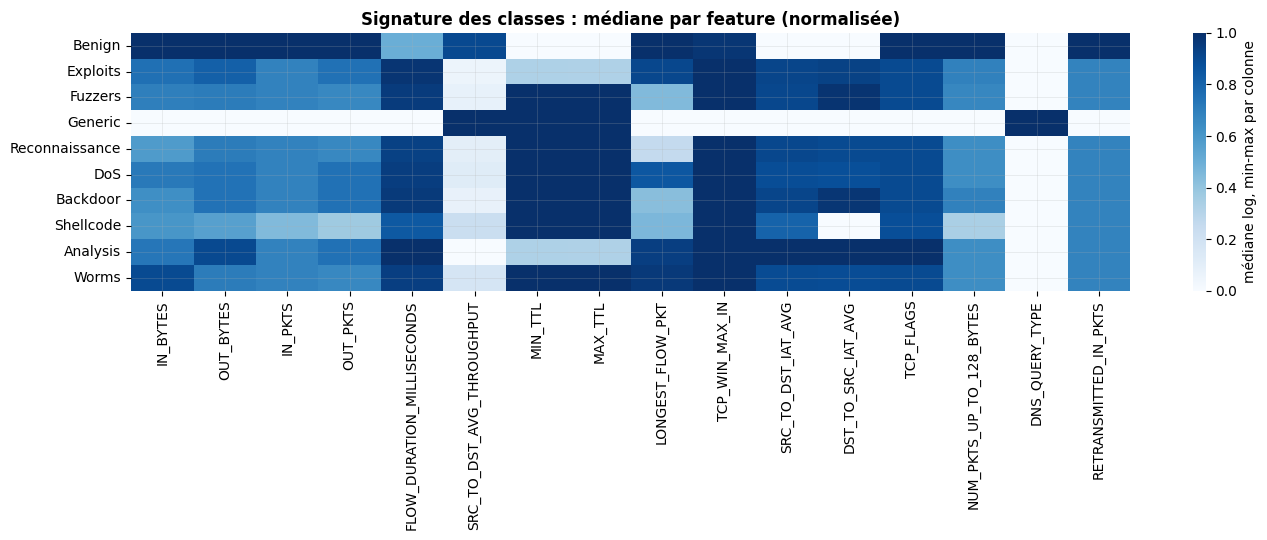

In [25]:
# Profil moyen (médianes) par classe, normalisé par feature pour comparer visuellement
prof_feats = key_feats + ["TCP_FLAGS", "NUM_PKTS_UP_TO_128_BYTES", "DNS_QUERY_TYPE", "RETRANSMITTED_IN_PKTS"]
prof = df.groupby("Attack", observed=True)[prof_feats].median().loc[order]
display(prof)

prof_norm = np.log1p(prof.astype(float))
prof_norm = (prof_norm - prof_norm.min()) / (prof_norm.max() - prof_norm.min()).replace(0, 1)
fig, ax = plt.subplots(figsize=(14, 5.5))
sns.heatmap(prof_norm, cmap=SEQ, ax=ax, cbar_kws={"label": "médiane log, min-max par colonne"})
ax.set_title("Signature des classes : médiane par feature (normalisée)")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

## 8. Corrélations

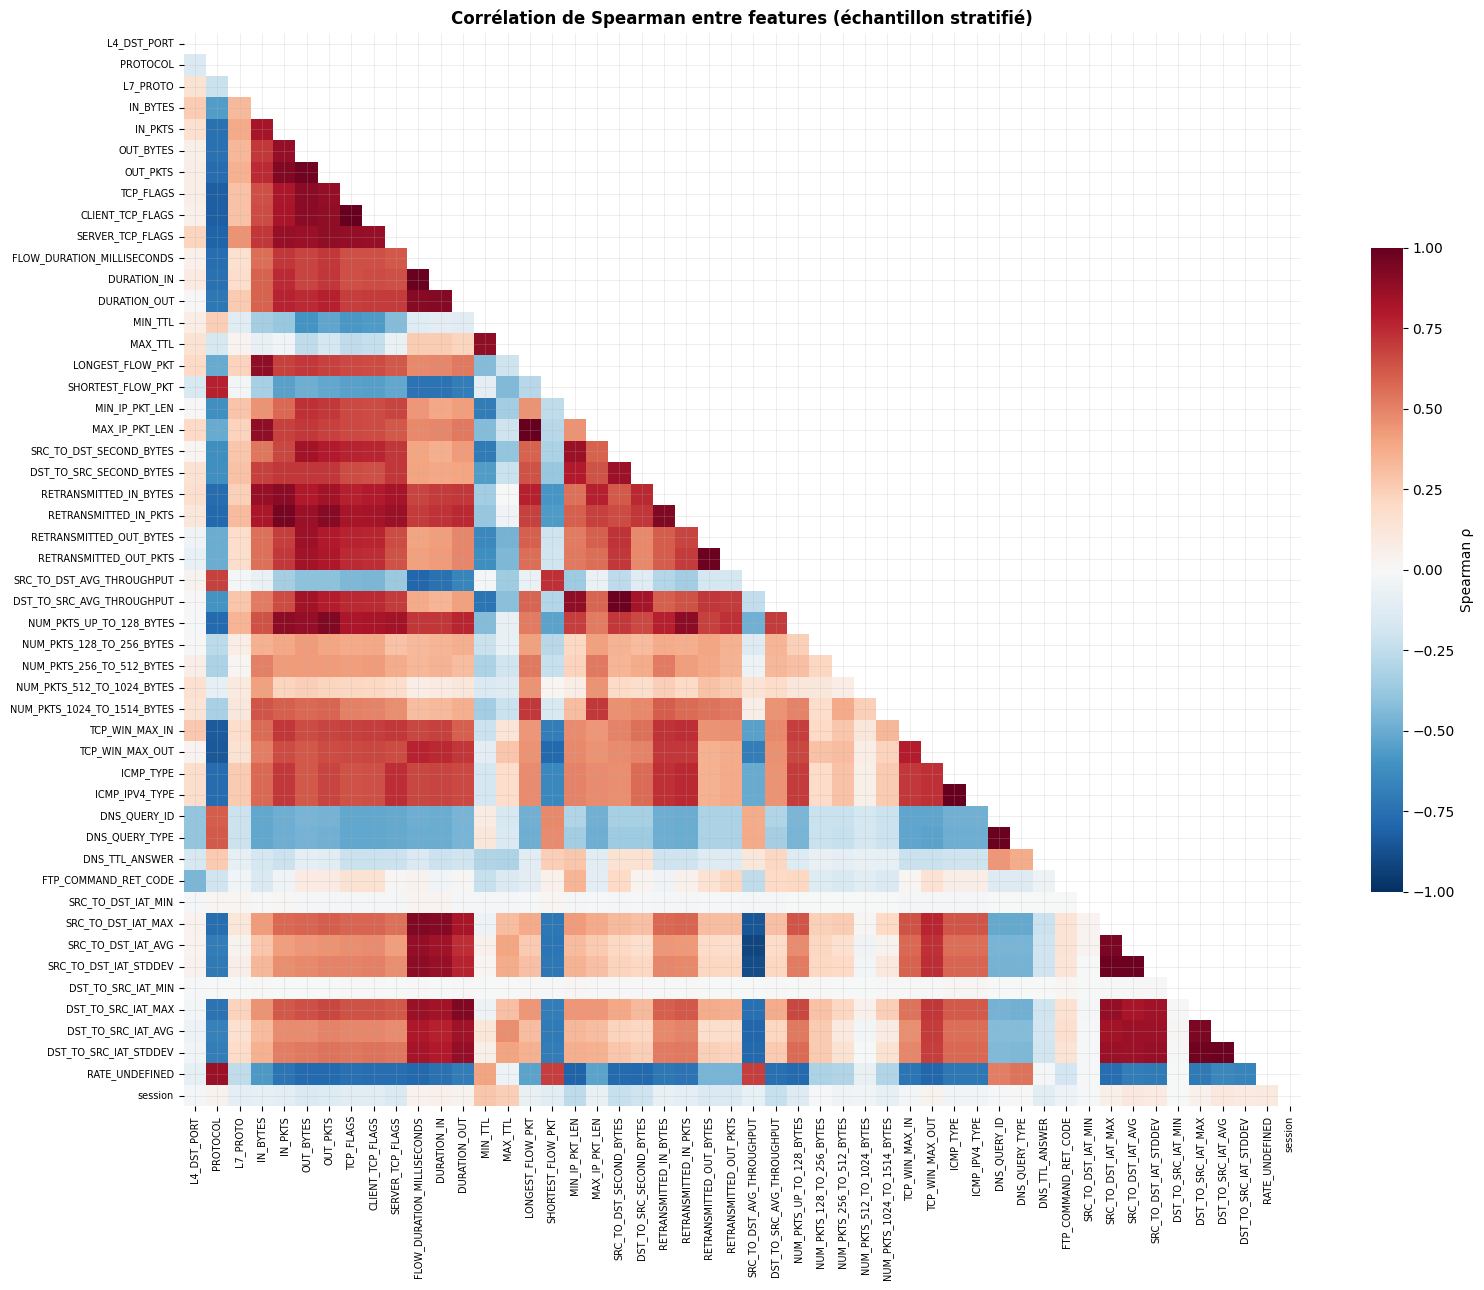

In [26]:
corr = sample[num_cols].astype(float).corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(corr, mask=mask, cmap=DIV, vmin=-1, vmax=1, center=0, ax=ax,
            xticklabels=True, yticklabels=True, cbar_kws={"shrink": 0.6, "label": "Spearman ρ"})
ax.tick_params(labelsize=7)
ax.set_title("Corrélation de Spearman entre features (échantillon stratifié)")
plt.tight_layout(); plt.show()

In [27]:
pairs = (corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1))
             .stack().rename("rho").reset_index())
pairs["abs"] = pairs["rho"].abs()
redundant = pairs[pairs["abs"] > 0.95].sort_values("abs", ascending=False)
print(f"{len(redundant)} paires avec |ρ| > 0.95 (features redondantes, candidates à la suppression)")
redundant.head(30)

13 paires avec |ρ| > 0.95 (features redondantes, candidates à la suppression)


,level_0,level_1,rho,abs
632,LONGEST_FLOW_PKT,MAX_IP_PKT_LEN,1.000,1.000
1105,ICMP_TYPE,ICMP_IPV4_TYPE,1.000,1.000
322,TCP_FLAGS,CLIENT_TCP_FLAGS,0.995,0.995
1134,DNS_QUERY_ID,DNS_QUERY_TYPE,0.990,0.990
445,FLOW_DURATION_MILLISECONDS,DURATION_IN,0.988,0.988
874,RETRANSMITTED_OUT_BYTES,RETRANSMITTED_OUT_PKTS,0.983,0.983
1197,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,0.982,0.982
1219,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,0.981,0.981
766,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_AVG_THROUGHPUT,0.980,0.980
1190,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_STDDEV,0.979,0.979


## 9. Importance des features (information mutuelle)

Mesure non linéaire de la dépendance entre chaque feature et la classe d'attaque.

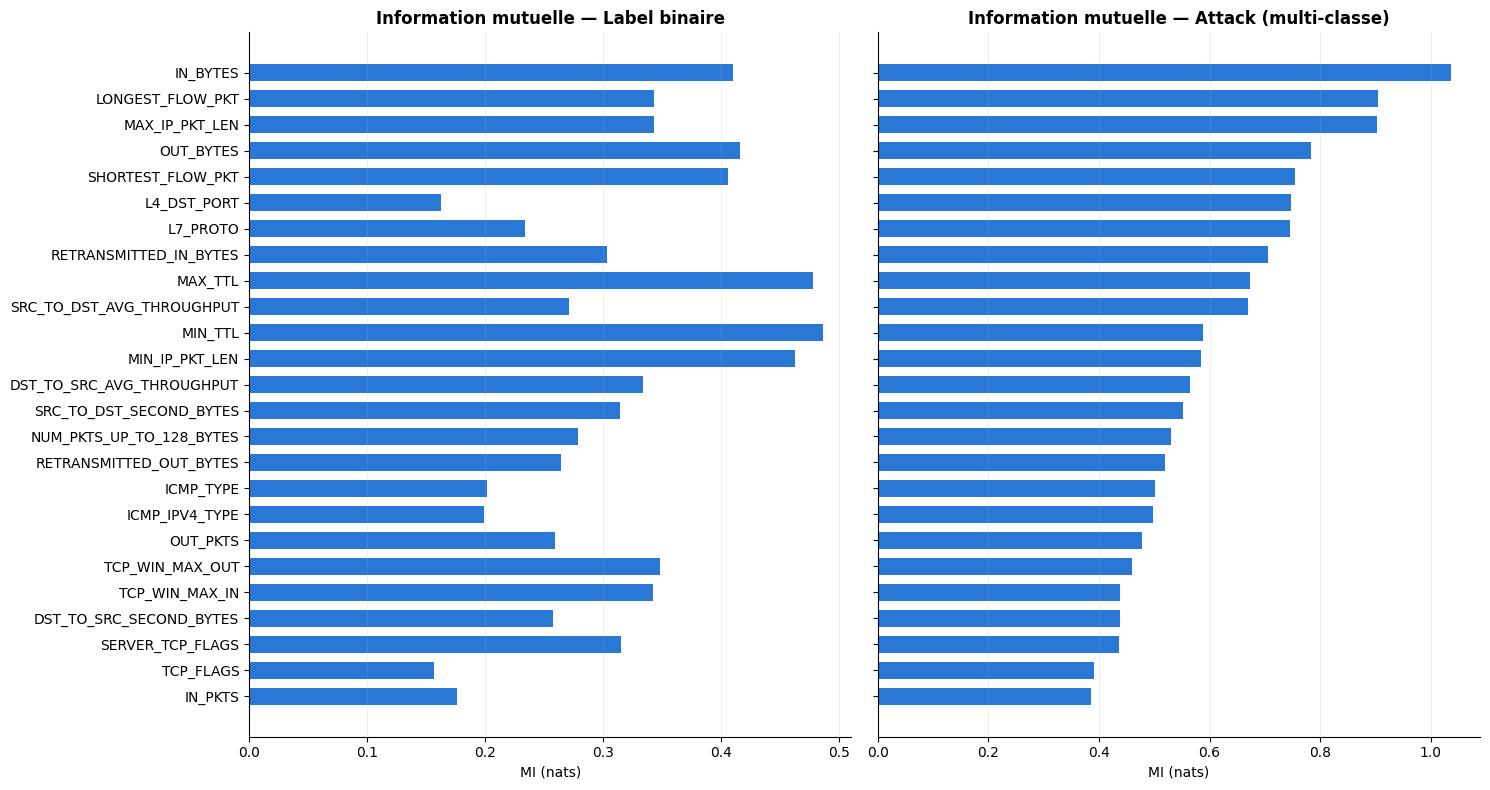

,MI_multiclasse,MI_binaire
IN_BYTES,1.037,0.410
LONGEST_FLOW_PKT,0.905,0.343
MAX_IP_PKT_LEN,0.903,0.343
OUT_BYTES,0.784,0.416
SHORTEST_FLOW_PKT,0.754,0.406
L4_DST_PORT,0.747,0.163
L7_PROTO,0.746,0.234
RETRANSMITTED_IN_BYTES,0.706,0.303
MAX_TTL,0.672,0.477
SRC_TO_DST_AVG_THROUGHPUT,0.669,0.271


In [28]:
from sklearn.feature_selection import mutual_info_classif

X = sample[num_cols].astype(float)
mi_multi = pd.Series(mutual_info_classif(X, sample["Attack"].astype(str), random_state=0), index=num_cols)
mi_bin = pd.Series(mutual_info_classif(X, sample["Label"], random_state=0), index=num_cols)
mi = pd.DataFrame({"MI_multiclasse": mi_multi, "MI_binaire": mi_bin}).sort_values("MI_multiclasse", ascending=False)

top = mi.head(25).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(15, 8), sharey=True)
axes[0].barh(top.index, top["MI_binaire"], color=C_BENIGN, height=0.65)
axes[0].set_title("Information mutuelle — Label binaire")
axes[1].barh(top.index, top["MI_multiclasse"], color=C_BENIGN, height=0.65)
axes[1].set_title("Information mutuelle — Attack (multi-classe)")
for ax in axes: ax.grid(axis="y", visible=False); ax.set_xlabel("MI (nats)")
plt.tight_layout(); plt.show()
mi.head(15)

## 10. Projection 2D (PCA)

Variance expliquée cumulée : [0.491 0.629 0.688 0.724 0.755 0.784 0.807 0.827 0.848 0.868]


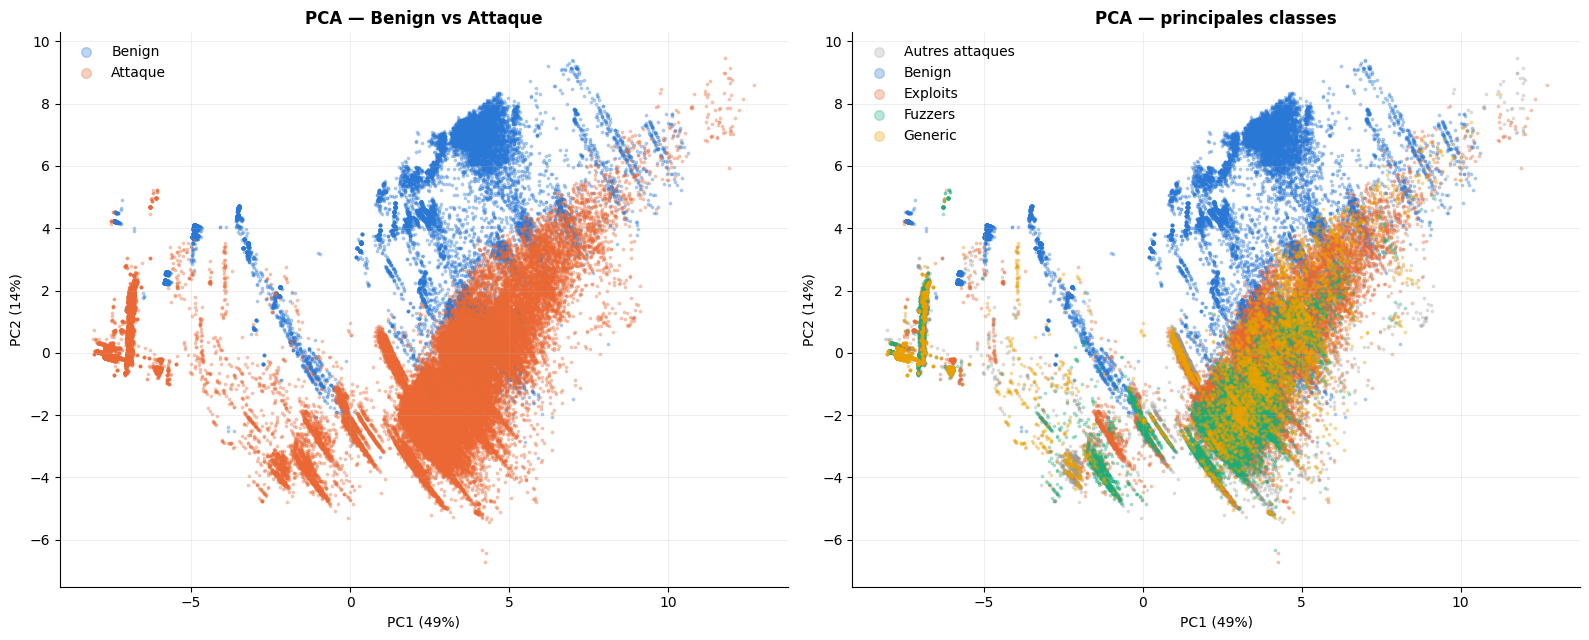

In [29]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

Xs = StandardScaler().fit_transform(np.log1p(X.clip(lower=0)))
pca = PCA(n_components=10, random_state=0).fit(Xs)
print("Variance expliquée cumulée :", np.round(np.cumsum(pca.explained_variance_ratio_), 3))
Z = pca.transform(Xs)[:, :2]

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
# Binaire
for lbl, color, name in [(0, C_BENIGN, "Benign"), (1, C_ATTACK, "Attaque")]:
    m = (sample["Label"] == lbl).values
    axes[0].scatter(Z[m, 0], Z[m, 1], s=3, alpha=0.3, color=color, label=name, rasterized=True)
axes[0].legend(frameon=False, markerscale=4)
axes[0].set_title("PCA — Benign vs Attaque")

# Multi-classe : 3 classes majoritaires d'attaque + Benign, reste regroupé en "Autres attaques" (gris)
top_att = [a for a in order if a != "Benign"][:3]
groups = [("Benign", PALETTE[0])] + list(zip(top_att, PALETTE[1:4]))
other = ~sample["Attack"].isin(["Benign"] + top_att).values
axes[1].scatter(Z[other, 0], Z[other, 1], s=3, alpha=0.25, color="#9a9994", label="Autres attaques", rasterized=True)
for name, color in groups:
    m = (sample["Attack"] == name).values
    axes[1].scatter(Z[m, 0], Z[m, 1], s=3, alpha=0.3, color=color, label=name, rasterized=True)
axes[1].legend(frameon=False, markerscale=4)
axes[1].set_title("PCA — principales classes")
for ax in axes:
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
plt.tight_layout(); plt.show()

## 11. Synthèse

**Volume & structure**
- ~2,37 M flux × 53 features + `Label` / `Attack`, 2 sessions de capture de ~12 h (22/01 et 18/02/2015), 40 IP sources / 40 IP destinations.

**Qualité**
- Pas de colonne constante ni de valeur négative.
- `SRC_TO_DST_SECOND_BYTES` / `DST_TO_SRC_SECOND_BYTES` : ~122 k valeurs NaN/inf, **toutes sur des flux de durée 0** (division par 0) → remplacées par 0 + indicateur `RATE_UNDEFINED`.
- ~0,6 % de lignes strictement dupliquées, mais **~55 % des flux partagent leur vecteur de features** avec un autre flux (une fois IP/ports/timestamps retirés). Aucun conflit de label. Risque de fuite train/test si on ne dédoublonne pas.

**Cible**
- Très déséquilibrée : 94,6 % Benign, 5,4 % attaques. `Worms` n'a que 158 flux, `Analysis` 1 226.
- → split stratifié, F1-macro / rappel par classe, poids de classes ou re-échantillonnage.

**Features « raccourcis » à surveiller**
- **IP source** : toutes les attaques viennent de `175.45.176.0/24`, aucun benign n'en vient → séparation parfaite. Les IP sont à exclure.
- **TTL** : médiane `MIN_TTL` = 31 pour Benign contre 62-254 pour les attaques. C'est un artefact du banc de test, qui ne se transposera probablement pas à un autre réseau.
- `L4_DST_PORT` / `L7_PROTO` sont très informatifs (les attaques visent peu de ports) : légitime, mais dépendant du scénario.

**Redondance**
- 13 paires avec |ρ| > 0,95 (ex. `LONGEST_FLOW_PKT` ≈ `MAX_IP_PKT_LEN`, `ICMP_TYPE` ≈ `ICMP_IPV4_TYPE`, `TCP_FLAGS` ≈ `CLIENT_TCP_FLAGS`) → on peut en retirer une de chaque paire.

**Séparabilité**
- Benign vs Attaque se sépare bien, déjà en PCA 2D. En revanche les classes d'attaque (Exploits, Fuzzers, Reconnaissance, DoS…) se chevauchent fortement : la difficulté est le **multi-classe**, surtout pour les classes rares.
- Features les plus informatives (information mutuelle) : `IN_BYTES`, `MAX_IP_PKT_LEN`/`LONGEST_FLOW_PKT`, `OUT_BYTES`, `SHORTEST_FLOW_PKT`, `L7_PROTO`, `L4_DST_PORT`, TTL.

**Prochaines étapes suggérées**
1. Retirer IP, `L4_SRC_PORT` et timestamps, et tester avec/sans TTL.
2. Dédoublonner avant le split (ou grouper les doublons dans le même fold).
3. Baseline : arbre de décision / Random Forest / LightGBM, binaire puis multi-classe.
4. Évaluer aussi sur un split par session (train sur une session, test sur l'autre).